<a href="https://colab.research.google.com/github/iamashwinijoshi/MNIST_Data_Preprocessing_lab/blob/main/MNistlab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from urllib import request
import numpy as np
import io

#specify the url dataset
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

#download the dataset files
with request.urlopen(url) as resp:
  data_bytes = resp.read()

#open the downloaded dataset
with np.load(io.BytesIO(data_bytes)) as data:
  print("Available arrays:",data.files)

  #extract images and their labels
  X_train = data['x_train']
  y_train = data['y_train']
  X_test = data['x_test']
  y_test = data['y_test']

print("\nMNIST dataset loaded successfully!!!")
print("your images and labels are ready to use..")
#inspects the dataset
print("\nTraining images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

print("\nImage data type:",X_train.dtype)
print("Label data type:",y_train.dtype)
print("Image data range:",X_train.min(),X_train.max())
print("Label data range:",y_train.min(),y_train.max())

Available arrays: ['x_test', 'x_train', 'y_train', 'y_test']

MNIST dataset loaded successfully!!!
your images and labels are ready to use..

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)

Image data type: uint8
Label data type: uint8
Image data range: 0 255
Label data range: 0 9


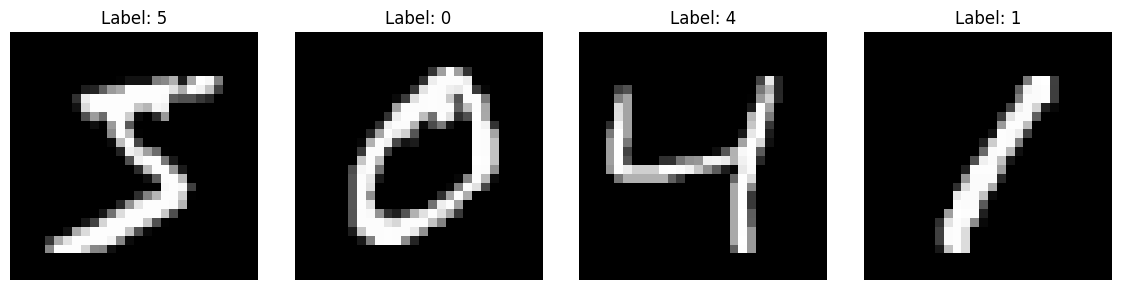

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,3))
for i in range(4):
  plt.subplot(1,4,i+1)
  plt.imshow(X_train[i],cmap='gray')
  plt.title(f"Label: {y_train[i]}")
  plt.axis('off')
  plt.tight_layout()
plt.show()

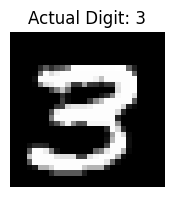

Image shape: (28, 28)
Image data type: uint8
Image data range: 0 255
Pixel value at raw 10: 108


In [ ]:
#displaying image and inspecting the peoperties
import matplotlib.pyplot as plt
#select the first image and label
image = X_train[111]
label = y_train[111]

#display the image
plt.figure(figsize=(2,4))
plt.imshow(image, cmap='gray')
plt.title(f"Actual Digit: {label}")
plt.axis('off')
plt.show()

#inspect the image
print("Image shape:",image.shape)
print("Image data type:",image.dtype)
print("Image data range:",image.min(),image.max())
print("Pixel value at raw 10:",image[10,10])

In [ ]:
# Create normalized floating point arrays
X_train_norm = X_train.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

# Compare the original and normalized data
print("Original dtype:", X_train.dtype)
print("Normalized dtype:", X_train_norm.dtype)

print("Original range:", X_train.min(), "to", X_train.max())
print("Normalized range:", X_train_norm.min(), "to", X_train_norm.max())

print("Original shape:", X_train.shape)
print("Normalized shape:", X_train_norm.shape)

# Inspect one pixel before and after normalization
print("Original pixel:", X_train[0, 10, 10])
print("Normalized pixel:", X_train_norm[0, 10, 10])

Original dtype: uint8
Normalized dtype: float32
Original range: 0 to 255
Normalized range: 0.0 to 1.0
Original shape: (60000, 28, 28)
Normalized shape: (60000, 28, 28)
Original pixel: 1
Normalized pixel: 0.003921569


In [ ]:
#installing the opencv lib for the gaussion blur processing becoz OpenCV can process the grayscale images in the MNIST datset  directly.
#%pip install opencv-python

5.0.0


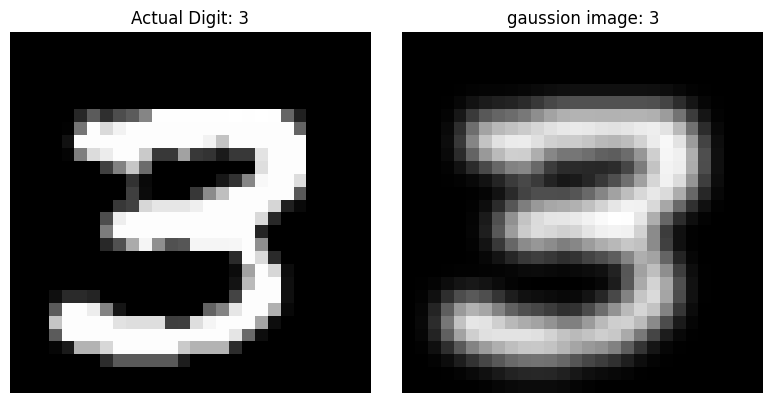

Original dtype: uint8
Blurred dtype: uint8
original shape:  (28, 28)
Blurred shape:  (28, 28)


In [ ]:
import cv2
print(cv2.__version__)

#lets select one image from the dataet
img = X_train[111]

#Now applying the gaussion blur on the image
blurred_image = cv2.GaussianBlur(img,(5,5),0)

#display the image
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title(f"Actual Digit: {label}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(blurred_image, cmap='gray')
plt.title(f"gaussion image: {label}")
plt.axis('off')

plt.tight_layout()
plt.show()

#inspecting the original image and the blurred images

print("Original dtype:", X_train.dtype)
print("Blurred dtype:", blurred_image.dtype)
print("original shape: ",img.shape)
print("Blurred shape: ",blurred_image.shape)

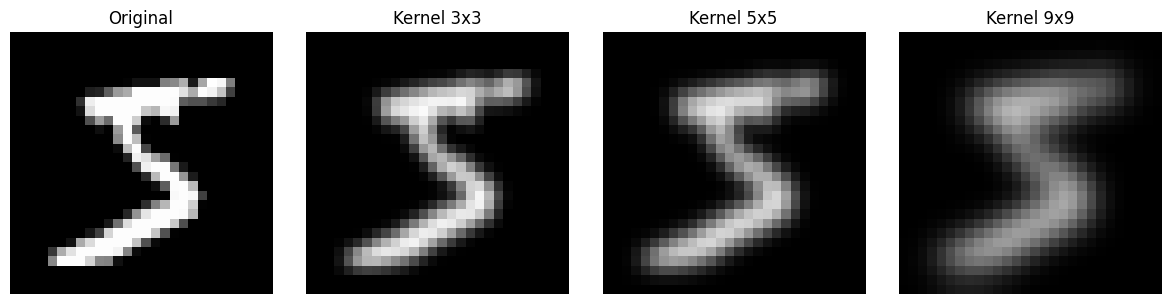

In [ ]:
image = X_train[0]

blur1 = cv2.GaussianBlur(image, (3, 3), 0)
blur2 = cv2.GaussianBlur(image, (5, 5), 0)
blur3 = cv2.GaussianBlur(image, (9, 9), 0)

plt.figure(figsize=(12, 3))

images = [
    (image, "Original"),
    (blur1, "Kernel 3x3"),
    (blur2, "Kernel 5x5"),
    (blur3, "Kernel 9x9")
]

for i, (img, title) in enumerate(images):
    plt.subplot(1, 4, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Blurred training shape: (60000, 28, 28)
Blurred testing shape: (10000, 28, 28)


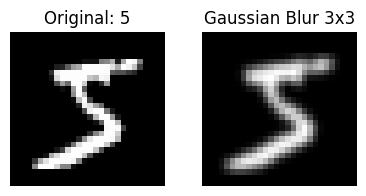

In [ ]:
#Applying Gaussian blur to all the images
X_train_blur = np.array([
    cv2.GaussianBlur(img, (3, 3), 0)
    for img in X_train
], dtype=np.uint8)

X_test_blur = np.array([
    cv2.GaussianBlur(img, (3, 3), 0)
    for img in X_test
], dtype=np.uint8)

# Normalize the blurred images
X_train_blur_norm = X_train_blur.astype("float32") / 255.0
X_test_blur_norm = X_test_blur.astype("float32") / 255.0

print("Blurred training shape:", X_train_blur_norm.shape)
print("Blurred testing shape:", X_test_blur_norm.shape)
#showing the blurred images for the visuals difference
index = 0

plt.figure(figsize=(4, 2))

plt.subplot(1, 2, 1)
plt.imshow(X_train[index], cmap="gray")
plt.title(f"Original: {y_train[index]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_train_blur[index], cmap="gray")
plt.title("Gaussian Blur 3x3")
plt.axis("off")

plt.tight_layout()
plt.show()

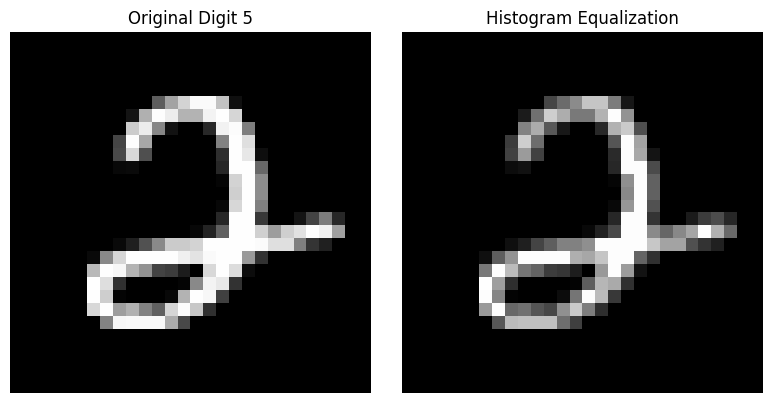

In [ ]:
#selection of the image
image = X_train[16]

# Apply histogram equalization
equalized_image = cv2.equalizeHist(image)

# Compare the images
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title(f"Original Digit {y_train[index]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()

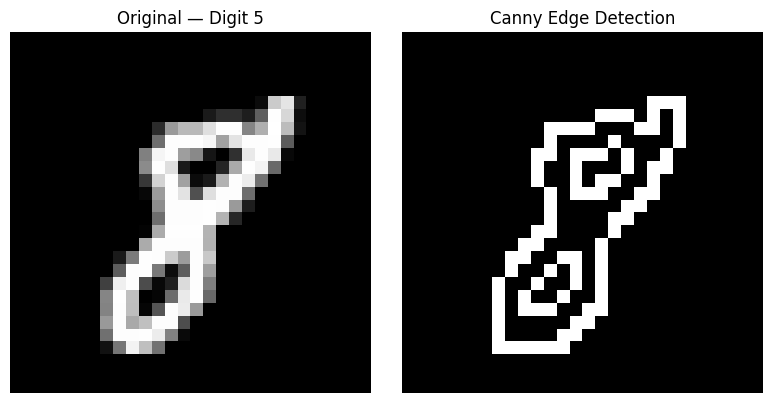

In [ ]:
#this is the edge detection using canny function from the openCV
# Select an image
image = X_train[17]

#Detect edges using canny function from the Cv2
edges = cv2.Canny(image, 100, 200)

#compare both the images
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title(f"Original — Digit {y_train[index]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()